#### AI in Production Management | Spring 2026 | Case Assignment
# Exercise 3: Data Preparation and Exploration for Sorting Line 3
#### The "Green Gold" Crisis at AlpenHarvest

This notebook ingests the raw dumps provided by Dave, documents the cleaning logic, builds a single analytical master table, and performs an EDA that can directly feed the slide deck for Exercise 3.

**Scope of this notebook**
- Validate the primary keys used to link machine and human-generated data
- Repair the Friday timestamp bug documented in the week 33 shift logbook
- Build a case-level master table anchored on `Case_ID`
- Audit missing values, consistency issues, duplicate sensor fields, and outliers
- Explore process patterns, label behavior, contextual factors, and shift-log insights


In [24]:
from pathlib import Path
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 12

DATA_DIR = Path("../data/DataDump_150825")
OUTPUT_DIR = Path("../outputs")
DOTENV_PATH = DOTENV_PATH = Path("../.env")
OUTPUT_DIR.mkdir(exist_ok=True)


pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 200)

def load_local_env_var(key: str, dotenv_path: Path = DOTENV_PATH):
    existing = os.getenv(key)
    if existing:
        return existing, "environment"

    if not dotenv_path.exists():
        return None, None

    for raw_line in dotenv_path.read_text(errors="ignore").splitlines():
        line = raw_line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        name, value = line.split("=", 1)
        if name.strip() != key:
            continue
        cleaned = value.strip().strip('"').strip("'")
        if cleaned:
            os.environ[key] = cleaned
            return cleaned, f"dotenv:{dotenv_path.name}"

    return None, None


## 1. Load the raw sources

The provided files span several operational layers:
- Object-level sorter measurements (`sensor_data_new.csv`)
- Manual quality outcomes (`quality_labels.csv`)
- Batch start records and operator attribution (`production_log_large.csv`)
- Operator master data (`operator_roster_large.csv`)
- Sparse machine status snapshots (`machine_status.csv`)
- Logistics context (`logistics_manifest.csv`)
- Unstructured operator logbooks for weeks 31 to 33


In [11]:
sensor = pd.read_csv(DATA_DIR / "sensor_data_new.csv")
quality = pd.read_csv(DATA_DIR / "quality_labels.csv")
production = pd.read_csv(DATA_DIR / "production_log_large.csv", parse_dates=["Timestamp"])
roster = pd.read_csv(DATA_DIR / "operator_roster_large.csv")
machine_status = pd.read_csv(DATA_DIR / "machine_status.csv", parse_dates=["Timestamp"])
logistics = pd.read_csv(DATA_DIR / "logistics_manifest.csv")

logbook_paths = [
    DATA_DIR / "SHN4_OERLIKON_CW3125.txt.txt",
    DATA_DIR / "SHN4_OERLIKON_CW3225.txt.txt",
    DATA_DIR / "SHN4_OERLIKON_CW3325.txt.txt",
]

source_overview = pd.DataFrame(
    [
        {"table": "sensor", "rows": len(sensor), "cols": sensor.shape[1], "grain": "one object / case"},
        {"table": "quality", "rows": len(quality), "cols": quality.shape[1], "grain": "one manually labeled case"},
        {"table": "production", "rows": len(production), "cols": production.shape[1], "grain": "one batch / charge"},
        {"table": "roster", "rows": len(roster), "cols": roster.shape[1], "grain": "one operator"},
        {"table": "machine_status", "rows": len(machine_status), "cols": machine_status.shape[1], "grain": "one parameter snapshot"},
        {"table": "logistics", "rows": len(logistics), "cols": logistics.shape[1], "grain": "one batch / charge"},
        {
            "table": "shift_logbooks",
            "rows": sum(path.read_text(errors="ignore").count("\n") + 1 for path in logbook_paths),
            "cols": 1,
            "grain": "free-text event log",
        },
    ]
)

display(source_overview)
display(sensor.head(3))
display(quality.head(3))


,table,rows,cols,grain
0,sensor,2006,35,one object / case
1,quality,1404,4,one manually labeled case
2,production,74,3,one batch / charge
3,roster,123,3,one operator
4,machine_status,16,3,one parameter snapshot
5,logistics,74,6,one batch / charge
6,shift_logbooks,1359,1,free-text event log


,Case_ID,Charge_ID,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33
0,23,0,61.0,1092.0,30,175,34,0,7,0,30,0,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,89,0,10,10,132,-137.0,22
1,32,0,41.0,778.0,21,105,21,0,6,0,17,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-48,0,4,4,112,-20.0,23
2,52,0,79.0,NaN,30,210,33,0,19,0,56,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,78,0,7,7,167,-91.0,43


,Case_ID,Manual_Label,Hash_Validation,Legacy_Quality_Score
0,10984,0,c35b8711,0.7750
1,8038,1,32bf471a,0.7712
2,10427,0,30e65371,0.1160


## 2. Validate join keys and repair timestamp consistency

The assignment explicitly asks us to show that machine data can be linked to the manual quality logs using a meaningful primary key. The data makes that join path clear:
- `Case_ID` is unique in both `sensor_data_new.csv` and `quality_labels.csv`
- all quality labels are a subset of the sensor cases
- `Charge_ID` links the sensor rows to production, logistics, and batch context

A major timestamp issue also appears in the raw dumps:
- some production and machine-status rows are stamped `2000-01-01`
- the week 33 logbook documents why: on **Friday, 15.08.2025 at 10:10**, the control PC reports `CMOS CHECKSUM ERROR` and the system date reverts to `01.01.2000`

I therefore repair all `year == 2000` records by keeping their time-of-day but replacing the date with `2025-08-15`.


In [12]:
assert sensor["Case_ID"].is_unique, "Case_ID should uniquely identify sensor rows."
assert quality["Case_ID"].is_unique, "Case_ID should uniquely identify quality rows."
assert set(quality["Case_ID"]).issubset(set(sensor["Case_ID"])), "Every quality label should map to a sensor case."
assert set(sensor["Charge_ID"]).issubset(set(production["Charge_ID"])), "Every sensor charge should have a production record."
assert set(production["Charge_ID"]) == set(logistics["Charge_ID"]), "Production and logistics should align at charge level."

def repair_friday_timestamp(ts: pd.Timestamp) -> pd.Timestamp:
    if ts.year != 2000:
        return ts
    return ts.replace(year=2025, month=8, day=15)

production["Timestamp_original"] = production["Timestamp"]
production["Timestamp_fixed"] = production["Timestamp"].apply(repair_friday_timestamp)

machine_status["Timestamp_original"] = machine_status["Timestamp"]
machine_status["Timestamp_fixed"] = machine_status["Timestamp"].apply(repair_friday_timestamp)

key_audit = pd.DataFrame(
    [
        {
            "check": "sensor Case_ID uniqueness",
            "result": sensor["Case_ID"].is_unique,
            "detail": f"{sensor['Case_ID'].nunique()} unique ids for {len(sensor)} rows",
        },
        {
            "check": "quality Case_ID uniqueness",
            "result": quality["Case_ID"].is_unique,
            "detail": f"{quality['Case_ID'].nunique()} unique ids for {len(quality)} rows",
        },
        {
            "check": "quality subset of sensor cases",
            "result": set(quality["Case_ID"]).issubset(set(sensor["Case_ID"])),
            "detail": f"{len(set(quality['Case_ID']) & set(sensor['Case_ID']))} overlapping cases",
        },
        {
            "check": "sensor Charge_ID covered by production",
            "result": set(sensor["Charge_ID"]).issubset(set(production["Charge_ID"])),
            "detail": f"{sensor['Charge_ID'].nunique()} charges in sensor data",
        },
    ]
)

timestamp_repairs = production.loc[
    production["Timestamp_original"].dt.year.eq(2000),
    ["Charge_ID", "Timestamp_original", "Timestamp_fixed", "Operator_ID"],
].sort_values("Timestamp_original")

display(key_audit)
print("Rows repaired in production_log_large.csv:", len(timestamp_repairs))
display(timestamp_repairs)

print("Rows repaired in machine_status.csv:", machine_status["Timestamp_original"].dt.year.eq(2000).sum())
display(machine_status.loc[machine_status["Timestamp_original"].dt.year.eq(2000), ["Timestamp_original", "Timestamp_fixed", "Parameter", "Value"]])


,check,result,detail
0,sensor Case_ID uniqueness,True,2006 unique ids for 2006 rows
1,quality Case_ID uniqueness,True,1404 unique ids for 1404 rows
2,quality subset of sensor cases,True,1404 overlapping cases
3,sensor Charge_ID covered by production,True,74 charges in sensor data


Rows repaired in production_log_large.csv: 12


,Charge_ID,Timestamp_original,Timestamp_fixed,Operator_ID
63,903,2000-01-01 11:18:50,2025-08-15 11:18:50,4786
64,904,2000-01-01 11:35:10,2025-08-15 11:35:10,4786
68,908,2000-01-01 12:24:37,2025-08-15 12:24:37,4786
65,905,2000-01-01 13:42:38,2025-08-15 13:42:38,4786
60,900,2000-01-01 16:03:03,2025-08-15 16:03:03,4786
66,906,2000-01-01 16:18:32,2025-08-15 16:18:32,4786
59,612,2000-01-01 16:52:50,2025-08-15 16:52:50,4786
67,907,2000-01-01 16:59:57,2025-08-15 16:59:57,4786
72,912,2000-01-01 18:06:11,2025-08-15 18:06:11,4786
69,909,2000-01-01 19:29:06,2025-08-15 19:29:06,4786


Rows repaired in machine_status.csv: 4


,Timestamp_original,Timestamp_fixed,Parameter,Value
12,2000-01-01 16:52:50,2025-08-15 16:52:50,Humidity_Pct,45.0
13,2000-01-01 16:52:50,2025-08-15 16:52:50,Belt_Speed_m_s,3.5
14,2000-01-01 19:29:06,2025-08-15 19:29:06,Humidity_Pct,45.0
15,2000-01-01 19:29:06,2025-08-15 19:29:06,Belt_Speed_m_s,1.5


## 3. Parse the shift logbooks into structured events

The logbooks are useful for three reasons:
- they give us the business explanation for the timestamp bug
- they expose process issues that do not appear in the structured tables
- they help qualify data fields that are technically present but operationally unreliable

I convert each raw text file into a structured event table with:
- `date`
- `time`
- `actor`
- `event`
- `body`
- issue tags inferred from the free text


In [13]:
def parse_logbooks(paths):
    rows = []
    current_date = None
    date_pattern = re.compile(r"^(MONDAY|TUESDAY|WEDNESDAY|THURSDAY|FRIDAY),\s+(\d{2}\.\d{2}\.\d{4})")
    header_pattern = re.compile(r"^\[(\d{2}:\d{2}:\d{2})\]\s+\[(.*?)\](?:\s+\[(.*?)\])?\s*$")

    for path in paths:
        lines = path.read_text(errors="ignore").splitlines()
        idx = 0
        while idx < len(lines):
            line = lines[idx]
            date_match = date_pattern.match(line)
            if date_match:
                current_date = pd.to_datetime(date_match.group(2), dayfirst=True).date()
                idx += 1
                continue

            header_match = header_pattern.match(line)
            if header_match:
                ts, actor, event = header_match.groups()
                body_lines = []
                j = idx + 1
                while j < len(lines) and lines[j].strip():
                    body_lines.append(lines[j].strip())
                    j += 1
                rows.append(
                    {
                        "source_file": path.name,
                        "date": current_date,
                        "time": ts,
                        "actor": actor,
                        "event": event,
                        "body": " ".join(body_lines),
                    }
                )
                idx = j + 1
                continue
            idx += 1

    events = pd.DataFrame(rows)
    events["timestamp"] = pd.to_datetime(events["date"].astype(str) + " " + events["time"])
    return events


ISSUE_PATTERNS = {
    "it_timekeeping": ["badge", "clock", "timesheet", "bios", "cmos", "year 2000", "server room", "thermal shutdown"],
    "yield_rejects": ["yield", "reject", "ejector", "rapid-firing", "warzone", "reject bin"],
    "packaging_tape": ["tape", "box", "blade", "packaging"],
    "contamination_logistics": ["plastic", "pallet", "gate", "truck", "rfid"],
    "sensor_configuration": ["feature 12", "feature 31", "density sensor", "brix", "scale change", "camera", "desync"],
    "maintenance": ["maintenance", "reboot", "firmware", "manifold", "compressor", "ticket"],
}


def tag_issues(text):
    lowered = text.lower()
    return [tag for tag, patterns in ISSUE_PATTERNS.items() if any(pattern in lowered for pattern in patterns)]


log_events = parse_logbooks(logbook_paths)
log_events["issue_tags"] = log_events["body"].apply(tag_issues)
log_events["issue_tag_count"] = log_events["issue_tags"].str.len()
log_events["week"] = pd.to_datetime(log_events["date"]).dt.isocalendar().week.astype(int)
log_events.to_csv(OUTPUT_DIR / "logbook_events_structured.csv", index=False)

display(log_events.head(10))
display(log_events["event"].value_counts().rename_axis("event_type").reset_index(name="count"))

week33 = log_events.loc[log_events["week"] == 33].copy()
notable_week33 = week33.loc[
    week33["issue_tag_count"] > 0,
    ["date", "time", "actor", "event", "issue_tags", "body"],
].head(12)
display(notable_week33)


,source_file,date,time,actor,event,body,timestamp,issue_tags,issue_tag_count,week
0,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,05:40:00,4031,MANUAL_LOG,Badge reader at the Sector 4 entrance is blink...,2025-07-28 05:40:00,[it_timekeeping],1,31
1,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,05:42:00,1691,MANUAL_LOG,Funny how the IT system always breaks when we ...,2025-07-28 05:42:00,[it_timekeeping],1,31
2,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,05:45:00,4786,SHIFT_START,Starting morning shift. Four days of productio...,2025-07-28 05:45:00,[],0,31
3,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,05:55:00,1691,MANUAL_LOG,Did anyone watch the Euro final in Basel yeste...,2025-07-28 05:55:00,[],0,31
4,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,06:10:00,8980,MANUAL_LOG,"1691, yes! I was at the public viewing near th...",2025-07-28 06:10:00,[],0,31
5,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,06:15:00,4786,MANUAL_LOG,"Hold everything! Before we start the feed, I a...",2025-07-28 06:15:00,[],0,31
6,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,06:18:00,8980,MANUAL_LOG,Happy work-anniversary to 7290! She brought th...,2025-07-28 06:18:00,[packaging_tape],1,31
7,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,06:20:00,8461,LOGISTICS_LOG,Charge_ID 88 arriving from Gate A. TransAlp. E...,2025-07-28 06:20:00,[contamination_logistics],1,31
8,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,06:35:00,4031,MANUAL_LOG,Belt speed set to 1.5 m/s. Everything sounds n...,2025-07-28 06:35:00,[],0,31
9,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,07:05:00,4786,MANUAL_LOG,"Line 3 is running, but the yield monitor is fl...",2025-07-28 07:05:00,[yield_rejects],1,31


,event_type,count
0,MANUAL_LOG,196
1,LOGISTICS_LOG,40
2,MAINTENANCE_TICKET,32
3,TECH_LOG,29
4,SHIFT_START,28
5,SHIFT_HANDOVER,27
6,QC_LOG,19
7,CLEANING_LOG,14
8,IT_ALERT,2
9,SYSTEM_KERNEL,1


,date,time,actor,event,issue_tags,body
314,2025-08-11,05:45:00,8980,MANUAL_LOG,[it_timekeeping],Badge reader at Sector 4 acting up. Swiped my ...
315,2025-08-11,06:30:00,8461,LOGISTICS_LOG,[contamination_logistics],First TransAlp truck at Gate A. Pallets are se...
318,2025-08-11,10:45:00,4467,MAINTENANCE_TICKET,[maintenance],Checking the air compressor oil levels for Lin...
321,2025-08-11,13:50:00,4786,SHIFT_HANDOVER,[it_timekeeping],My shift is ending. Katya (7662) is stuck in H...
329,2025-08-11,19:30:00,6254,CLEANING_LOG,[packaging_tape],Emptying bio-waste bins near the packaging sta...
333,2025-08-12,05:50:00,8980,MANUAL_LOG,[it_timekeeping],I knew it! Checked the HR portal. My badge did...
335,2025-08-12,07:45:00,3898,QC_LOG,[contamination_logistics],Morning calibration check with the standard gr...
338,2025-08-12,11:30:00,4031,MANUAL_LOG,"[yield_rejects, sensor_configuration]",Yield fluctuating. Side cameras compensating f...
346,2025-08-12,20:10:00,9689,CLEANING_LOG,[contamination_logistics],Mopping the loading dock area near Gate B. Sli...
352,2025-08-13,11:15:00,9901,LOGISTICS_LOG,[contamination_logistics],Moving a stack of empty Euro-Pool pallets from...


## 4. Audit missing values, redundant fields, and feature quality

Before merging anything into a master table, the raw sorter feature set itself needs cleaning:
- `feature_1`, `feature_2`, and `feature_32` contain missing values
- several columns are constant zero fields and carry no analytical signal
- several other columns are exact duplicates of each other

I keep the raw sensor table untouched for traceability, but I define a reduced feature list for analysis that removes constant columns and duplicate copies.


In [14]:
feature_cols = [col for col in sensor.columns if col.startswith("feature_")]

missing_summary = (
    sensor[feature_cols]
    .isna()
    .sum()
    .rename("missing_rows")
    .reset_index()
    .rename(columns={"index": "feature"})
    .assign(missing_pct=lambda df: df["missing_rows"] / len(sensor))
    .sort_values(["missing_rows", "feature"], ascending=[False, True])
)

nunique = sensor[feature_cols].nunique(dropna=False)
constant_features = nunique[nunique <= 1].index.tolist()

duplicate_groups = []
visited = set(constant_features)
for col in feature_cols:
    if col in visited:
        continue
    group = [col]
    visited.add(col)
    for other in feature_cols:
        if other in visited:
            continue
        if sensor[col].fillna("__NA__").equals(sensor[other].fillna("__NA__")):
            group.append(other)
            visited.add(other)
    if len(group) > 1:
        duplicate_groups.append(group)

duplicate_drop = [col for group in duplicate_groups for col in group[1:]]
analytic_features = [col for col in feature_cols if col not in constant_features + duplicate_drop]

duplicate_overview = pd.DataFrame(
    [{"kept_feature": group[0], "duplicate_copies": ", ".join(group[1:])} for group in duplicate_groups]
)
quality_audit = pd.DataFrame(
    [
        {"metric": "raw sensor features", "value": len(feature_cols)},
        {"metric": "features with missing values", "value": int((missing_summary["missing_rows"] > 0).sum())},
        {"metric": "constant features", "value": len(constant_features)},
        {"metric": "duplicate feature copies dropped from EDA", "value": len(duplicate_drop)},
        {"metric": "analytic features retained", "value": len(analytic_features)},
    ]
)

display(quality_audit)
display(missing_summary.head(10))
display(duplicate_overview.head(10))

print("Constant features:", constant_features)
print("Analytic features retained:", analytic_features)


,metric,value
0,raw sensor features,33
1,features with missing values,3
2,constant features,17
3,duplicate feature copies dropped from EDA,1
4,analytic features retained,15


,feature,missing_rows,missing_pct
31,feature_32,315,0.157029
1,feature_2,276,0.137587
0,feature_1,216,0.107677
9,feature_10,0,0.000000
10,feature_11,0,0.000000
11,feature_12,0,0.000000
12,feature_13,0,0.000000
13,feature_14,0,0.000000
14,feature_15,0,0.000000
15,feature_16,0,0.000000


,kept_feature,duplicate_copies
0,feature_29,feature_30


Constant features: ['feature_6', 'feature_8', 'feature_13', 'feature_14', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_19', 'feature_20', 'feature_21', 'feature_22', 'feature_23', 'feature_24', 'feature_25', 'feature_26', 'feature_28']
Analytic features retained: ['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_7', 'feature_9', 'feature_10', 'feature_11', 'feature_12', 'feature_27', 'feature_29', 'feature_31', 'feature_32', 'feature_33']


## 5. Build the master table

The analytical grain is one object / case, anchored on `Case_ID`. The merge path is:

`sensor (Case_ID, Charge_ID)`  
`-> quality via Case_ID`  
`-> production, logistics via Charge_ID`  
`-> operator name/role via Operator_ID`  
`-> machine status via exact corrected batch timestamp`

Two caveats from the logbook are kept visible in the master table:
- operator attribution is not perfectly reliable because PLC sessions were reused during handovers
- machine-status enrichment is sparse because only a handful of timestamps match exactly


In [15]:
status_wide = (
    machine_status
    .pivot_table(
        index="Timestamp_fixed",
        columns="Parameter",
        values="Value",
        aggfunc="first",
    )
    .reset_index()
)

master = (
    sensor
    .merge(quality, on="Case_ID", how="left", validate="one_to_one")
    .merge(
        production[["Charge_ID", "Timestamp_fixed", "Operator_ID"]],
        on="Charge_ID",
        how="left",
        validate="many_to_one",
    )
    .merge(roster, on="Operator_ID", how="left", validate="many_to_one")
    .merge(logistics, on="Charge_ID", how="left", validate="many_to_one")
    .merge(status_wide, on="Timestamp_fixed", how="left", validate="many_to_one")
)

master["production_date"] = master["Timestamp_fixed"].dt.date
master["production_hour"] = master["Timestamp_fixed"].dt.hour + master["Timestamp_fixed"].dt.minute / 60
master["shift_guess"] = np.where(master["Timestamp_fixed"].dt.hour < 14, "Morning", "Late")
master["label_available"] = master["Manual_Label"].notna()
master["operator_attribution_note"] = "Observed production log id"

katya_under_urs = (
    master["Charge_ID"].isin([4, 2])
    & (master["production_date"] == pd.to_datetime("2025-08-11").date())
)
master.loc[katya_under_urs, "operator_attribution_note"] = "Logbook says Katya used Urs' logged-in PLC session"

master_table_path = OUTPUT_DIR / "exercise3_master_table_case_level.csv"
master.to_csv(master_table_path, index=False)

charge_summary = (
    master
    .groupby("Charge_ID")
    .agg(
        n_cases=("Case_ID", "size"),
        labeled_cases=("label_available", "sum"),
        defect_rate=("Manual_Label", "mean"),
        timestamp=("Timestamp_fixed", "first"),
        operator_name=("Name", "first"),
        provider=("Logistics_Provider", "first"),
        pallet_type=("Pallet_Type", "first"),
        arrival_gate=("Arrival_Gate", "first"),
        humidity_pct=("Humidity_Pct", "first"),
        belt_speed_m_s=("Belt_Speed_m_s", "first"),
    )
    .reset_index()
    .sort_values("timestamp")
)

display(master.head(5))
display(charge_summary.head(12))
print(f"Master table saved to: {master_table_path}")
print("Share of cases with manual labels:", round(master["label_available"].mean(), 3))
print("Share of cases with exact machine-status enrichment:", round(master["Humidity_Pct"].notna().mean(), 3))


,Case_ID,Charge_ID,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,Manual_Label,Hash_Validation,Legacy_Quality_Score,Timestamp_fixed,Operator_ID,Name,Role,Logistics_Provider,Truck_Plate,Arrival_Gate,Pallet_Type,RFID_Tag,Belt_Speed_m_s,Humidity_Pct,production_date,production_hour,shift_guess,label_available,operator_attribution_note
0,23,0,61.0,1092.0,30,175,34,0,7,0,30,0,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,89,0,10,10,132,-137.0,22,NaN,NaN,NaN,2025-08-11 11:31:30,4786,Urs Mueller,Shift Lead,SpeedyLogistics,ZH-30392,Gate B,Euro-Pool,A8021EB0318D33B4,1.5,45.0,2025-08-11,11.516667,Morning,False,Observed production log id
1,32,0,41.0,778.0,21,105,21,0,6,0,17,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-48,0,4,4,112,-20.0,23,0.0,7a551341,0.1996,2025-08-11 11:31:30,4786,Urs Mueller,Shift Lead,SpeedyLogistics,ZH-30392,Gate B,Euro-Pool,A8021EB0318D33B4,1.5,45.0,2025-08-11,11.516667,Morning,True,Observed production log id
2,52,0,79.0,NaN,30,210,33,0,19,0,56,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,78,0,7,7,167,-91.0,43,0.0,3c407aa4,0.4581,2025-08-11 11:31:30,4786,Urs Mueller,Shift Lead,SpeedyLogistics,ZH-30392,Gate B,Euro-Pool,A8021EB0318D33B4,1.5,45.0,2025-08-11,11.516667,Morning,True,Observed production log id
3,60,0,49.0,1119.0,34,160,28,0,10,0,47,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,92,0,10,10,162,NaN,17,NaN,NaN,NaN,2025-08-11 11:31:30,4786,Urs Mueller,Shift Lead,SpeedyLogistics,ZH-30392,Gate B,Euro-Pool,A8021EB0318D33B4,1.5,45.0,2025-08-11,11.516667,Morning,False,Observed production log id
4,69,0,91.0,NaN,39,210,35,0,13,0,33,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,3,3,154,-28.0,74,NaN,NaN,NaN,2025-08-11 11:31:30,4786,Urs Mueller,Shift Lead,SpeedyLogistics,ZH-30392,Gate B,Euro-Pool,A8021EB0318D33B4,1.5,45.0,2025-08-11,11.516667,Morning,False,Observed production log id


,Charge_ID,n_cases,labeled_cases,defect_rate,timestamp,operator_name,provider,pallet_type,arrival_gate,humidity_pct,belt_speed_m_s
12,12,62,43,0.046512,2025-08-11 07:27:48,Urs Mueller,TransAlp,Plastic,Gate A,NaN,NaN
14,300,15,10,0.700000,2025-08-11 10:50:14,Urs Mueller,SpeedyLogistics,Plastic,Gate B,NaN,NaN
11,11,72,48,0.062500,2025-08-11 11:05:05,Urs Mueller,SpeedyLogistics,Plastic,Gate A,NaN,NaN
0,0,64,39,0.025641,2025-08-11 11:31:30,Urs Mueller,SpeedyLogistics,Euro-Pool,Gate B,45.0,1.5
10,10,60,37,0.000000,2025-08-11 11:43:56,Urs Mueller,TransAlp,Plastic,Gate A,45.0,1.5
3,3,62,47,0.000000,2025-08-11 12:35:38,Urs Mueller,SpeedyLogistics,Euro-Pool,Gate B,NaN,NaN
13,13,1,1,0.000000,2025-08-11 13:22:58,Dave Liebknecht,SpeedyLogistics,Euro-Pool,Gate A,NaN,NaN
1,1,68,45,0.355556,2025-08-11 13:56:11,Dave Liebknecht,SpeedyLogistics,Euro-Pool,Gate A,NaN,NaN
7,7,66,50,0.340000,2025-08-11 14:07:43,Dave Liebknecht,SpeedyLogistics,Euro-Pool,Gate B,NaN,NaN
9,9,75,56,0.214286,2025-08-11 15:26:15,Dave Liebknecht,SpeedyLogistics,Euro-Pool,Gate A,NaN,NaN


Master table saved to: ../outputs/exercise3_master_table_case_level.csv
Share of cases with manual labels: 0.7
Share of cases with exact machine-status enrichment: 0.11


## 6. EDA: production rhythm, label coverage, and process trend

First I check whether the corrected timestamps produce a sensible weekly production view:
- object volume by day
- labeled defect share by day
- batch start distribution over the day
- charge-level defect rates over time


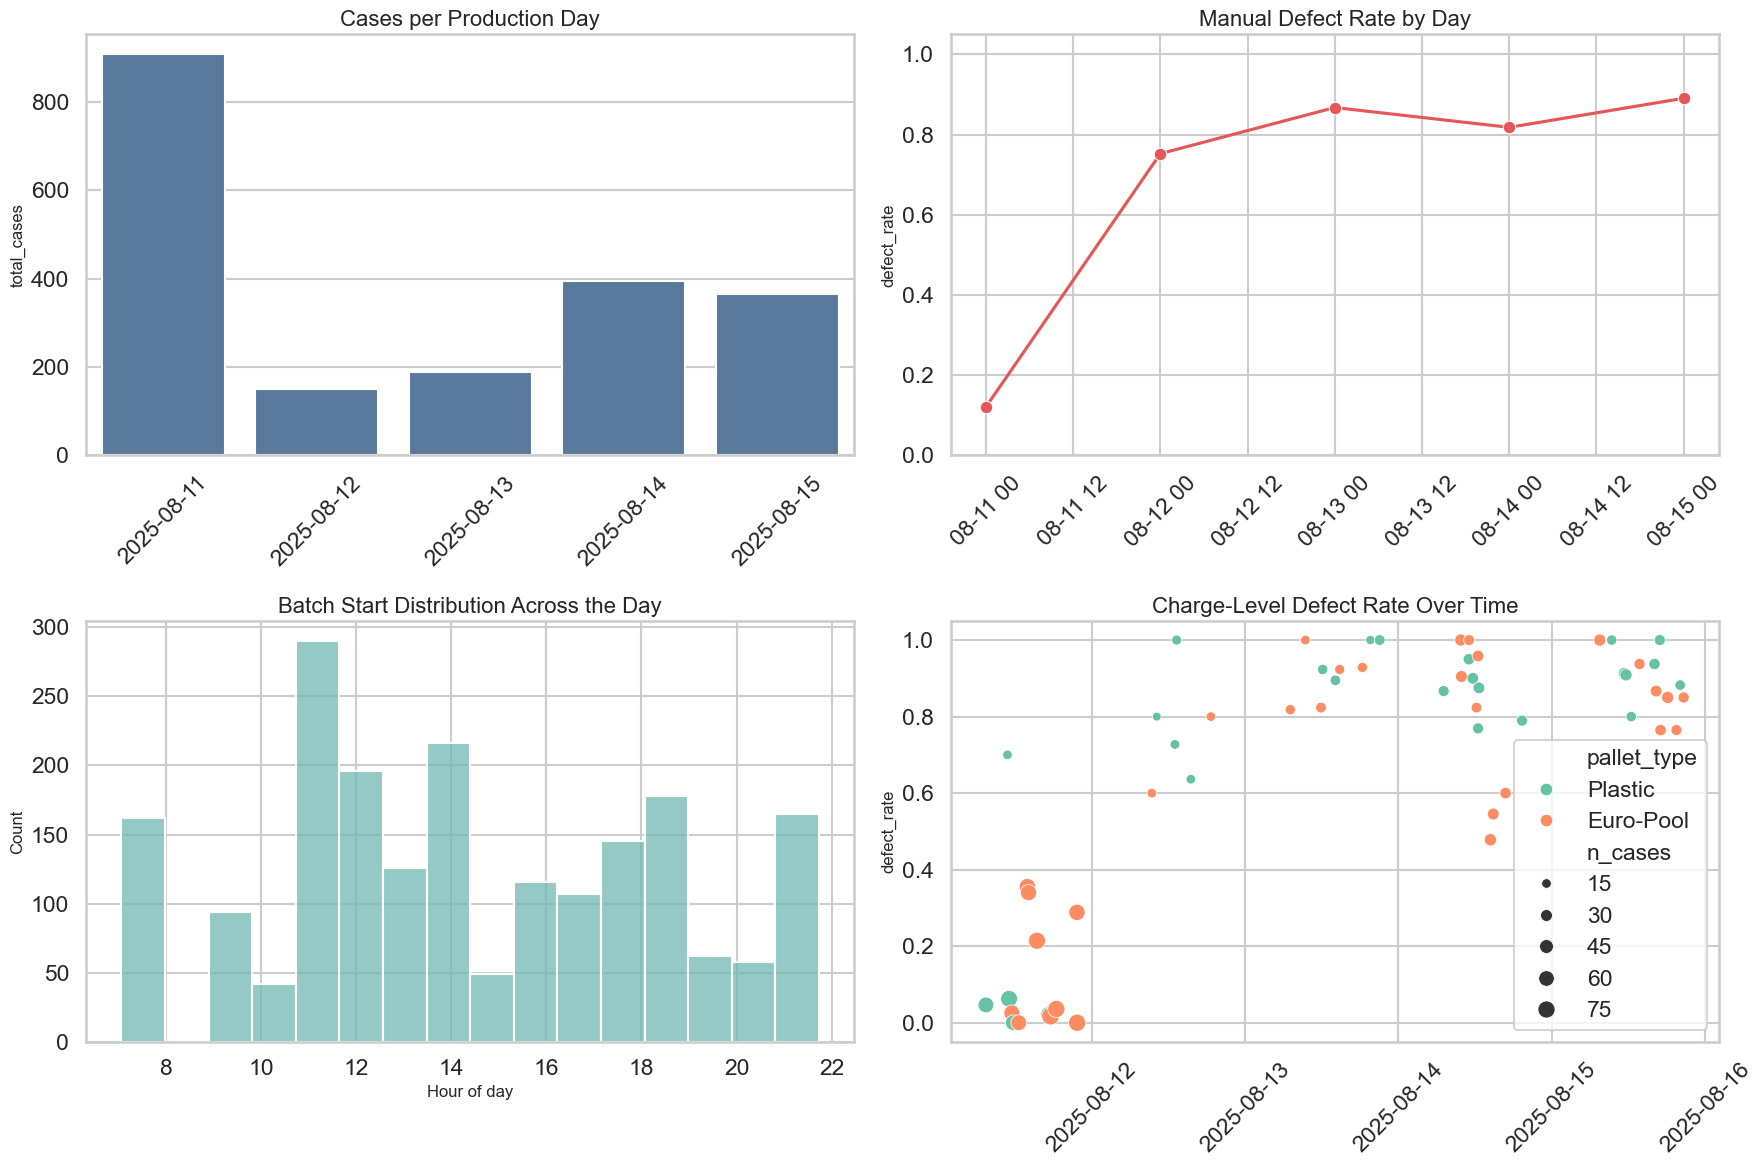

,production_date,total_cases,labeled_cases,unique_charges,label_coverage_pct
0,2025-08-11,908,638,15,0.702643
1,2025-08-12,150,97,15,0.646667
2,2025-08-13,188,136,15,0.723404
3,2025-08-14,394,286,15,0.725888
4,2025-08-15,366,247,14,0.674863


,production_date,labeled_rows,defect_rate
0,2025-08-11,638,0.120690
1,2025-08-12,97,0.752577
2,2025-08-13,136,0.867647
3,2025-08-14,286,0.818182
4,2025-08-15,247,0.890688


In [16]:
labeled_master = master.dropna(subset=["Manual_Label"]).copy()

daily_summary = (
    master.groupby("production_date")
    .agg(
        total_cases=("Case_ID", "size"),
        labeled_cases=("label_available", "sum"),
        unique_charges=("Charge_ID", "nunique"),
    )
    .reset_index()
)
daily_summary["label_coverage_pct"] = daily_summary["labeled_cases"] / daily_summary["total_cases"]

daily_defect = (
    labeled_master.groupby("production_date")["Manual_Label"]
    .agg(["count", "mean"])
    .reset_index()
    .rename(columns={"count": "labeled_rows", "mean": "defect_rate"})
)

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

sns.barplot(data=daily_summary, x="production_date", y="total_cases", ax=axes[0, 0], color="#4C78A8")
axes[0, 0].set_title("Cases per Production Day")
axes[0, 0].set_xlabel("")
axes[0, 0].tick_params(axis="x", rotation=45)

sns.lineplot(data=daily_defect, x="production_date", y="defect_rate", marker="o", ax=axes[0, 1], color="#E45756")
axes[0, 1].set_title("Manual Defect Rate by Day")
axes[0, 1].set_xlabel("")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].set_ylim(0, 1.05)

sns.histplot(master["production_hour"], bins=16, ax=axes[1, 0], color="#72B7B2")
axes[1, 0].set_title("Batch Start Distribution Across the Day")
axes[1, 0].set_xlabel("Hour of day")

plot_charge = charge_summary.loc[charge_summary["labeled_cases"] >= 10].copy()
sns.scatterplot(
    data=plot_charge,
    x="timestamp",
    y="defect_rate",
    hue="pallet_type",
    size="n_cases",
    ax=axes[1, 1],
    palette="Set2",
)
axes[1, 1].set_title("Charge-Level Defect Rate Over Time")
axes[1, 1].set_xlabel("")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.show()

display(daily_summary)
display(daily_defect)


## 7. EDA: explicit data-quality findings

The brief explicitly asks us to discuss consistency, missing values, and outliers. I treat each one separately:

- **Consistency**: broken timestamps, unreliable operator attribution during handovers, constant feature fields, and duplicate feature copies
- **Missing values**: only three sensor fields show nulls, but they matter because they are also informative features
- **Outliers**: I flag them with a simple IQR rule to understand scale and concentration, not to drop them blindly


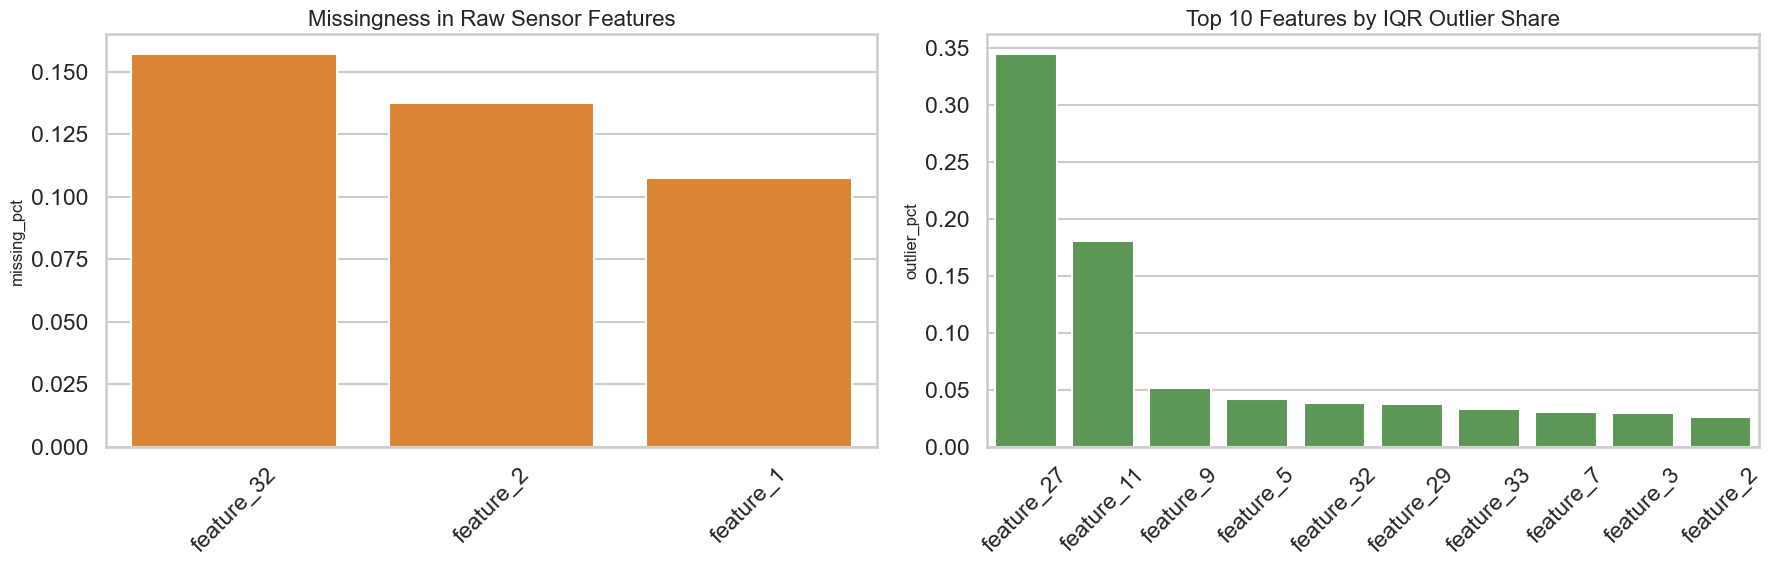

,issue,treatment
0,Timestamp bug,Repaired all year-2000 rows to 2025-08-15 usin...
1,Missing sensor values,Keep as nulls in master table; use median impu...
2,Constant and duplicate features,"Retain raw columns for audit, exclude redundan..."
3,Outliers,Flag with IQR rule; inspect before removal bec...
4,Operator attribution,Keep observed IDs but annotate known handover ...


,feature,missing_rows,outlier_rows,outlier_pct
10,feature_27,0,692,0.344965
8,feature_11,0,362,0.180459
6,feature_9,0,103,0.051346
4,feature_5,0,85,0.042373
13,feature_32,315,77,0.038385
11,feature_29,0,75,0.037388
14,feature_33,0,67,0.033400
5,feature_7,0,62,0.030907
2,feature_3,0,59,0.029412
1,feature_2,276,53,0.026421


In [17]:
outlier_rows = []
for col in analytic_features:
    series = sensor[col].dropna()
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_count = ((sensor[col] < lower) | (sensor[col] > upper)).sum()
    outlier_rows.append(
        {
            "feature": col,
            "missing_rows": int(sensor[col].isna().sum()),
            "outlier_rows": int(outlier_count),
            "outlier_pct": outlier_count / len(sensor),
        }
    )

outlier_summary = pd.DataFrame(outlier_rows).sort_values("outlier_pct", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

missing_plot = missing_summary.loc[missing_summary["missing_rows"] > 0].copy()
sns.barplot(data=missing_plot, x="feature", y="missing_pct", ax=axes[0], color="#F58518")
axes[0].set_title("Missingness in Raw Sensor Features")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(data=outlier_summary.head(10), x="feature", y="outlier_pct", ax=axes[1], color="#54A24B")
axes[1].set_title("Top 10 Features by IQR Outlier Share")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

quality_findings = pd.DataFrame(
    [
        {"issue": "Timestamp bug", "treatment": "Repaired all year-2000 rows to 2025-08-15 using logbook evidence"},
        {"issue": "Missing sensor values", "treatment": "Keep as nulls in master table; use median imputation only for modeling later"},
        {"issue": "Constant and duplicate features", "treatment": "Retain raw columns for audit, exclude redundant copies from EDA feature set"},
        {"issue": "Outliers", "treatment": "Flag with IQR rule; inspect before removal because some may represent true process anomalies"},
        {"issue": "Operator attribution", "treatment": "Keep observed IDs but annotate known handover exceptions from the logbook"},
    ]
)

display(quality_findings)
display(outlier_summary.head(15))


## 8. EDA: which sensor features move with quality?

To get an interpretable view, I use the labeled subset only and rank features by the absolute difference in class means. This is not a final model. It is a screening step for variables worth investigating further.


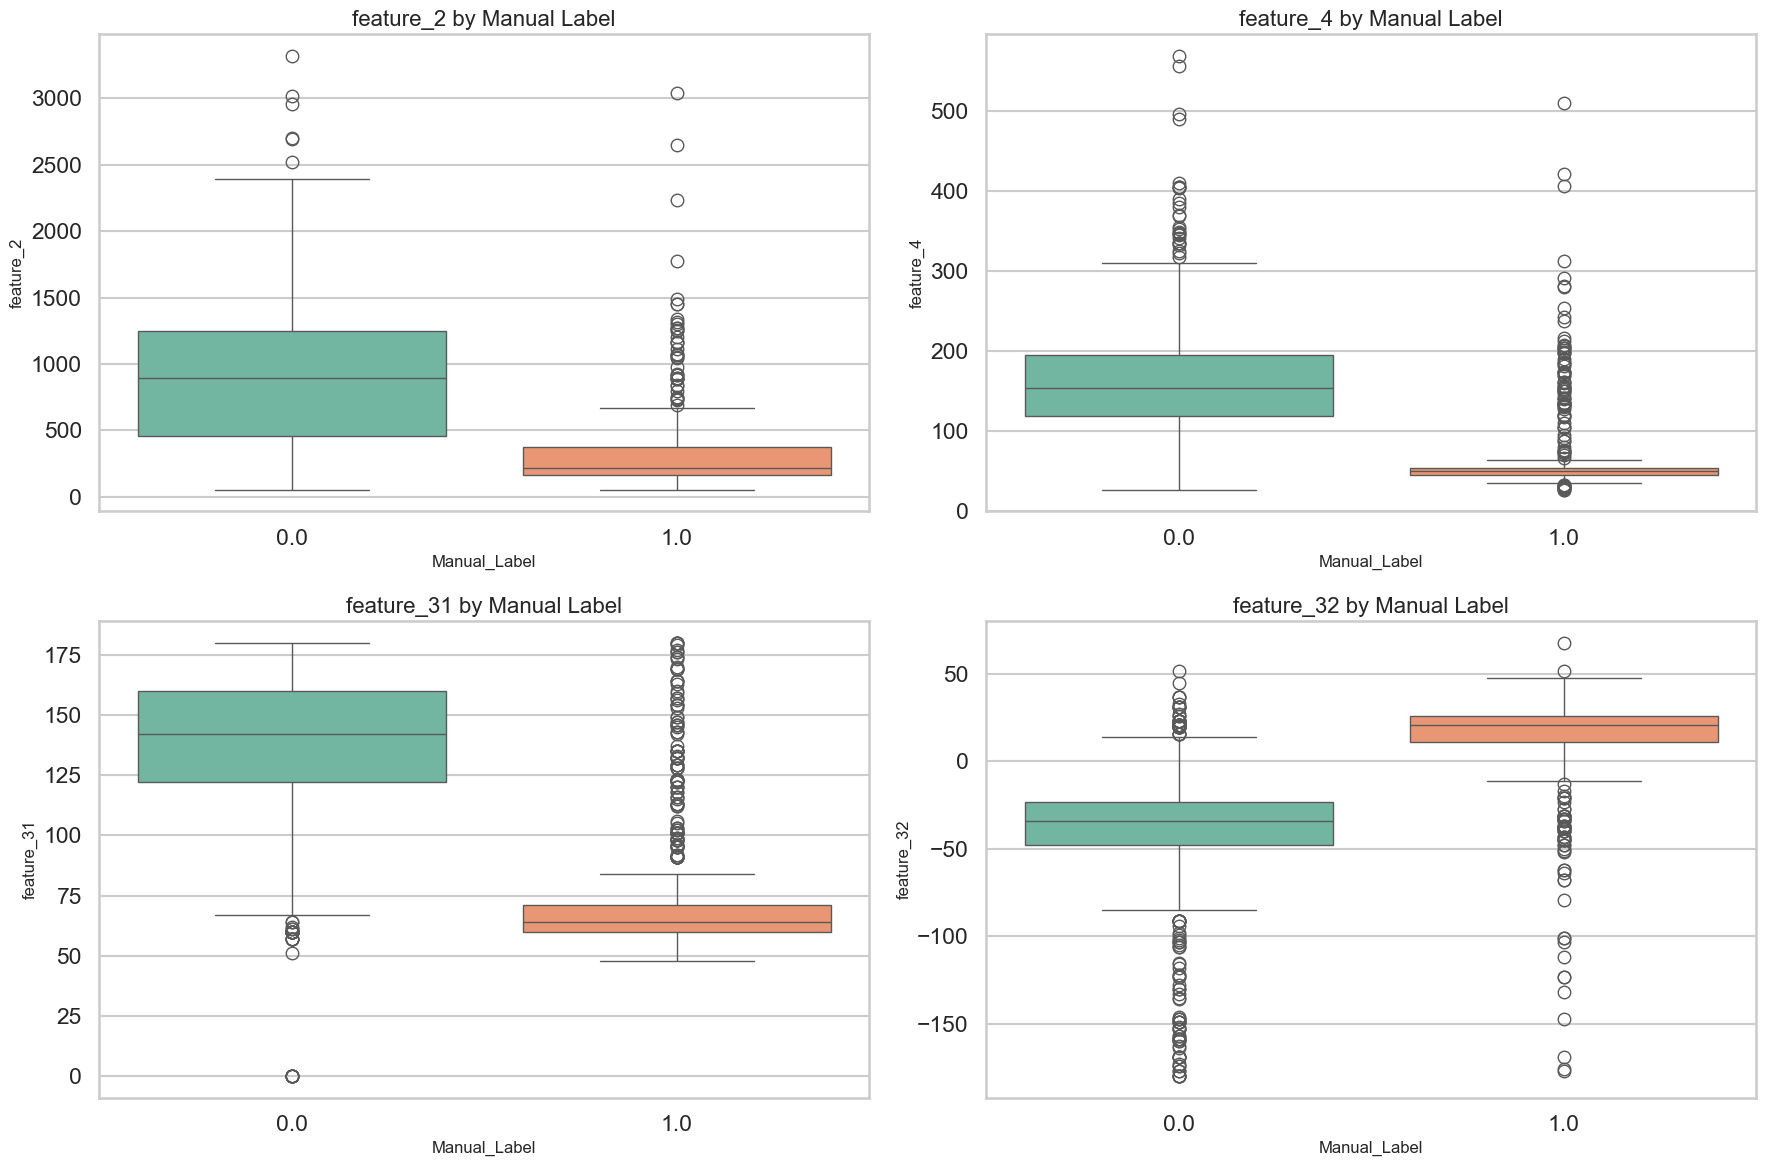

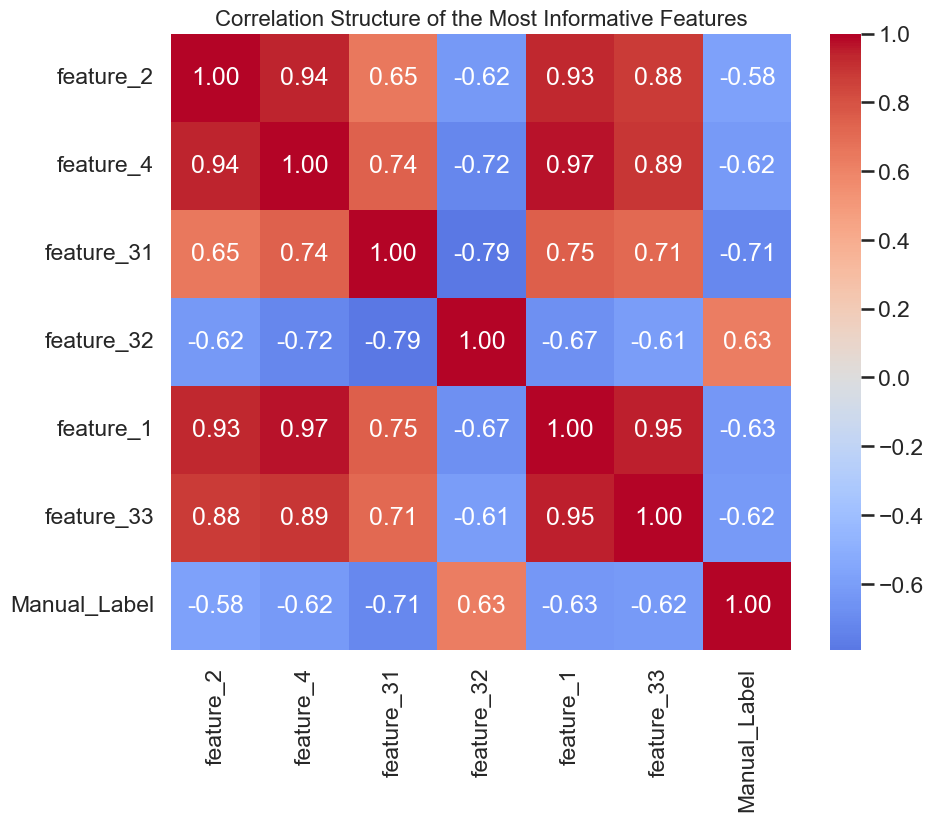

,feature,mean_label_0,mean_label_1,abs_mean_gap,corr_with_label
1,feature_2,921.521318,300.527378,620.993940,-0.580872
3,feature_4,160.851906,60.554017,100.297890,-0.620148
12,feature_31,136.589443,74.534626,62.054817,-0.710751
13,feature_32,-43.606000,14.903179,58.509179,0.628954
0,feature_1,61.840198,20.478939,41.361259,-0.633371
14,feature_33,39.693548,5.500000,34.193548,-0.620100
10,feature_27,28.595308,1.152355,27.442953,-0.278578
6,feature_9,36.136364,12.333795,23.802569,-0.511439
4,feature_5,30.755132,14.853186,15.901946,-0.548442
2,feature_3,27.206745,15.941828,11.264917,-0.555969


In [18]:
labeled_sensor = master.dropna(subset=["Manual_Label"]).copy()

feature_screen = []
for col in analytic_features:
    grouped = labeled_sensor.groupby("Manual_Label")[col].mean()
    feature_screen.append(
        {
            "feature": col,
            "mean_label_0": grouped.get(0, np.nan),
            "mean_label_1": grouped.get(1, np.nan),
            "abs_mean_gap": abs(grouped.get(1, np.nan) - grouped.get(0, np.nan)),
            "corr_with_label": labeled_sensor[[col, "Manual_Label"]].corr().iloc[0, 1],
        }
    )

feature_screen = pd.DataFrame(feature_screen).sort_values("abs_mean_gap", ascending=False)
top_features = feature_screen.head(6)["feature"].tolist()

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
for ax, col in zip(axes.flatten(), top_features[:4]):
    sns.boxplot(data=labeled_sensor, x="Manual_Label", y=col, ax=ax, palette="Set2")
    ax.set_title(f"{col} by Manual Label")

plt.tight_layout()
plt.show()

corr_features = top_features[:6] + ["Manual_Label"]
plt.figure(figsize=(10, 8))
sns.heatmap(labeled_sensor[corr_features].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Structure of the Most Informative Features")
plt.show()

display(feature_screen.head(12))


## 9. EDA: operational context and batch effects

The structured context tables help answer whether defect behavior clusters by batch conditions rather than just object-level geometry:
- logistics provider
- pallet type
- arrival gate
- observed operator
- exact machine-status snapshot, when available


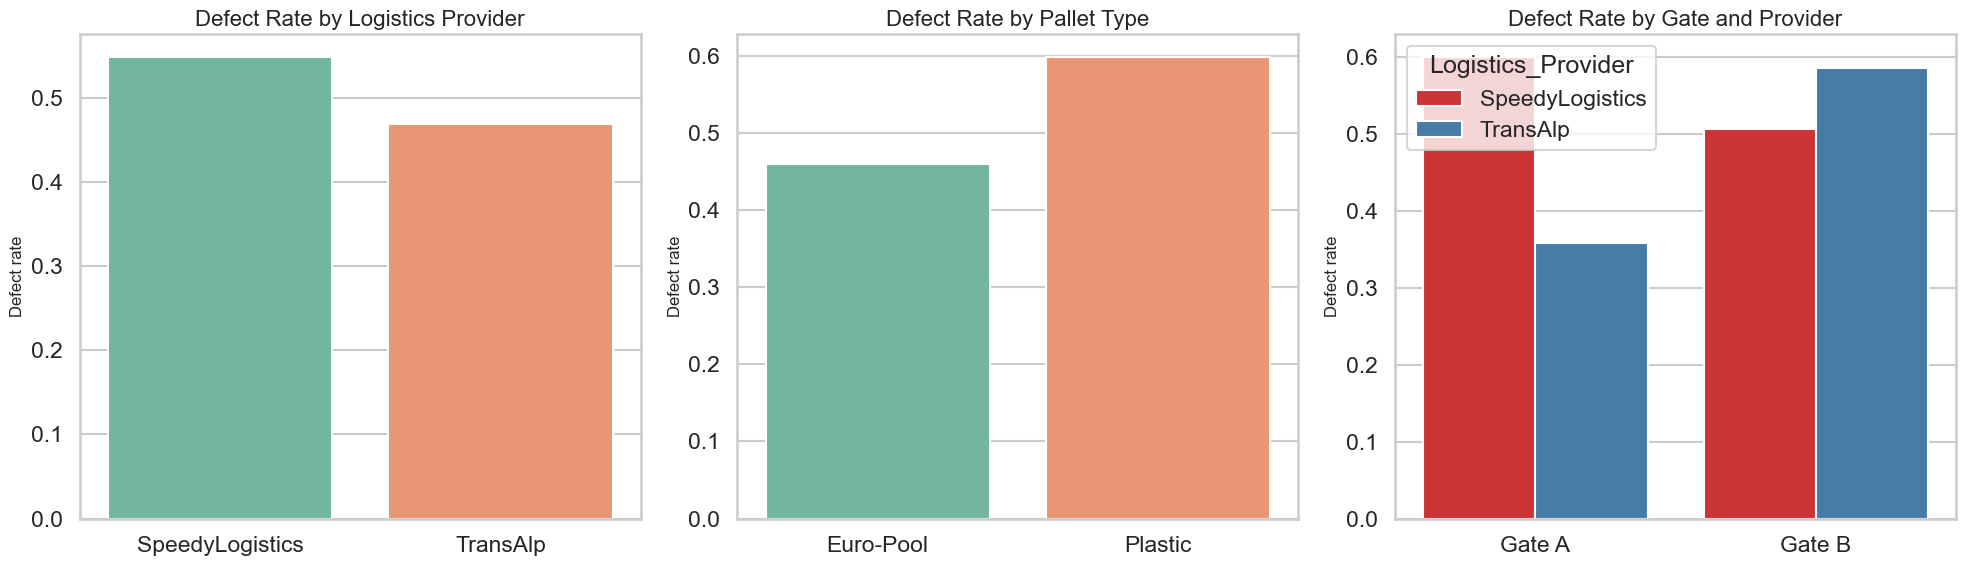

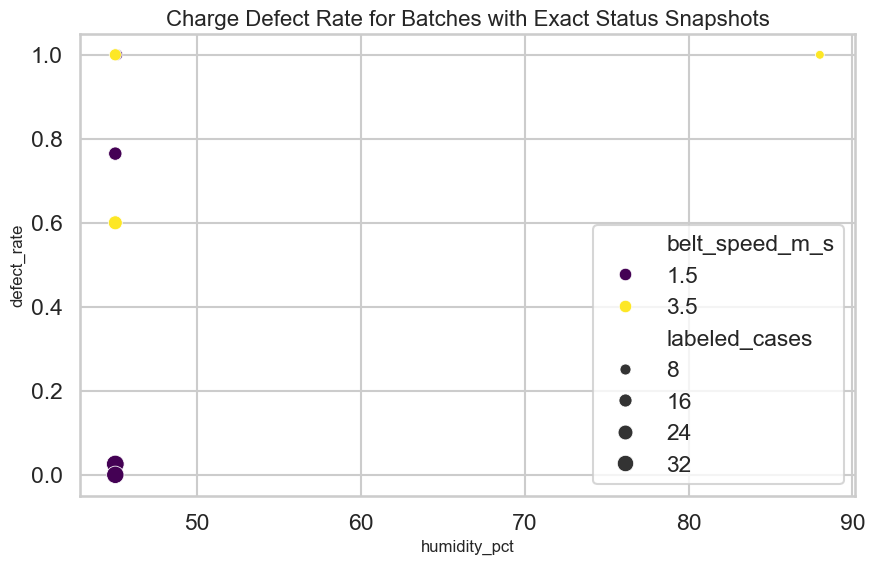

,Charge_ID,n_cases,labeled_cases,defect_rate,timestamp,operator_name,provider,pallet_type,arrival_gate,humidity_pct,belt_speed_m_s
38,504,22,15,1.000000,2025-08-13 21:03:55,Urs Mueller,TransAlp,Plastic,Gate A,NaN,NaN
71,911,20,15,1.000000,2025-08-15 09:21:25,Urs Mueller,TransAlp,Plastic,Gate B,NaN,NaN
42,508,13,12,1.000000,2025-08-13 19:35:57,Urs Mueller,TransAlp,Plastic,Gate A,NaN,NaN
39,505,15,10,1.000000,2025-08-13 09:25:41,Urs Mueller,SpeedyLogistics,Euro-Pool,Gate A,45.1,1.5
59,612,24,12,1.000000,2025-08-15 16:52:50,Urs Mueller,SpeedyLogistics,Plastic,Gate B,45.0,3.5
53,606,31,22,1.000000,2025-08-14 09:44:03,Urs Mueller,SpeedyLogistics,Euro-Pool,Gate A,NaN,NaN
26,312,17,10,1.000000,2025-08-12 13:18:10,Urs Mueller,SpeedyLogistics,Plastic,Gate B,NaN,NaN
52,605,23,17,1.000000,2025-08-14 11:02:31,Urs Mueller,SpeedyLogistics,Euro-Pool,Gate B,NaN,NaN
61,901,32,22,1.000000,2025-08-15 07:29:27,Urs Mueller,TransAlp,Euro-Pool,Gate B,NaN,NaN
57,610,28,24,0.958333,2025-08-14 12:26:19,Urs Mueller,TransAlp,Euro-Pool,Gate B,NaN,NaN


In [19]:
context_plots = labeled_master.copy()

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.barplot(
    data=context_plots.groupby("Logistics_Provider", as_index=False)["Manual_Label"].mean(),
    x="Logistics_Provider",
    y="Manual_Label",
    ax=axes[0],
    palette="Set2",
)
axes[0].set_title("Defect Rate by Logistics Provider")
axes[0].set_xlabel("")
axes[0].set_ylabel("Defect rate")

sns.barplot(
    data=context_plots.groupby("Pallet_Type", as_index=False)["Manual_Label"].mean(),
    x="Pallet_Type",
    y="Manual_Label",
    ax=axes[1],
    palette="Set2",
)
axes[1].set_title("Defect Rate by Pallet Type")
axes[1].set_xlabel("")
axes[1].set_ylabel("Defect rate")

provider_gate = (
    context_plots.groupby(["Arrival_Gate", "Logistics_Provider"], as_index=False)["Manual_Label"].mean()
)
sns.barplot(
    data=provider_gate,
    x="Arrival_Gate",
    y="Manual_Label",
    hue="Logistics_Provider",
    ax=axes[2],
    palette="Set1",
)
axes[2].set_title("Defect Rate by Gate and Provider")
axes[2].set_xlabel("")
axes[2].set_ylabel("Defect rate")

plt.tight_layout()
plt.show()

status_charge_view = charge_summary.loc[charge_summary["humidity_pct"].notna()].copy()
if not status_charge_view.empty:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=status_charge_view,
        x="humidity_pct",
        y="defect_rate",
        hue="belt_speed_m_s",
        size="labeled_cases",
        palette="viridis",
    )
    plt.title("Charge Defect Rate for Batches with Exact Status Snapshots")
    plt.ylim(-0.05, 1.05)
    plt.show()

display(
    charge_summary.loc[charge_summary["labeled_cases"] >= 10]
    .sort_values("defect_rate", ascending=False)
    .head(12)
)


## 10. Logbook synthesis and LLM-ready digest

The logbooks materially enrich the structured data in at least four ways:
- they explain the Friday year-2000 timestamps
- they show that operator IDs can be contaminated by session reuse
- they reveal process and maintenance incidents outside the core batch tables
- they surface domain constraints, such as **Feature 31 (Brix) being destructive and unsuitable for real-time sorting**

The code below creates a deterministic synthesis that runs without external credentials. For teammates, the optional LLM call works if either of these is set up:
- `GROQ_API_KEY` in the shell environment
- a local `Case/.env` file containing `GROQ_API_KEY=...`

Groq is used here because it offers a free-tier API and is compatible with the Python `openai` client when we point it to Groq's base URL.

Recommended team workflow:
1. Copy `.env.example` to `.env`
2. Paste your own Groq API key into `.env`
3. Re-run this section


In [25]:

issue_counts = (
    log_events.explode("issue_tags")
    .dropna(subset=["issue_tags"])
    .groupby(["week", "issue_tags"])
    .size()
    .reset_index(name="count")
    .sort_values(["week", "count"], ascending=[True, False])
)

critical_log_excerpt = log_events.loc[
    log_events["body"].str.contains("CMOS CHECKSUM ERROR|Feature 31|year 2000|used Urs", case=False, regex=True, na=False),
    ["date", "time", "actor", "event", "body"],
].copy()

logbook_digest = {
    "Historical pattern": "Week 31 logs describe aggressive false rejects on the left side of the belt and severe yield loss.",
    "Packaging / logistics": "Week 32 logs document tape shortages, pallet contamination concerns, and density-sensor issues caused by ice clumps.",
    "Timestamp integrity": "Week 33 explicitly records a thermal shutdown and BIOS date reset to 01.01.2000 on Friday morning.",
    "Governance caveat": "Week 33 warns that Feature 31 (Brix) is destructive and should not be used for real-time sorting.",
    "Attribution caveat": "Week 33 notes that Katya ran batches under Urs' still-open PLC session, so production_log operator IDs are not perfect ground truth.",
}

display(issue_counts)
display(critical_log_excerpt)
display(Markdown("\n".join([f"- **{k}:** {v}" for k, v in logbook_digest.items()])))

prompt_payload = "\n".join(
    [
        "Summarize the operational insights from the AlpenHarvest Sorting Line 3 shift logbooks.",
        "Focus on data quality, process disruptions, and what the logbook adds beyond the structured tables.",
        "",
        "Critical excerpts:",
        critical_log_excerpt.to_csv(index=False),
    ]
)

llm_summary = None
api_key, api_key_source = load_local_env_var("GROQ_API_KEY")
try:
    from openai import OpenAI

    if api_key:
        client = OpenAI(
            api_key=api_key,
            base_url="https://api.groq.com/openai/v1",
        )
        response = client.responses.create(
            model="openai/gpt-oss-20b",
            input=prompt_payload,
        )
        llm_summary = f"Loaded Groq API key from {api_key_source}.\n\n{response.output_text.strip()}"
    else:
        llm_summary = (
            "Optional LLM step skipped because GROQ_API_KEY was not found "
            f"in the environment or in {DOTENV_PATH}. "
            "The deterministic synthesis above is the executed fallback."
        )
except Exception as exc:
    llm_summary = f"Optional LLM step skipped ({type(exc).__name__}: {exc}). The deterministic synthesis above is the executed fallback."

display(Markdown(f"**LLM step:** {llm_summary}"))


,week,issue_tags,count
5,31,yield_rejects,29
4,31,sensor_configuration,15
2,31,maintenance,13
0,31,contamination_logistics,11
3,31,packaging_tape,4
1,31,it_timekeeping,2
9,32,packaging_tape,76
11,32,yield_rejects,28
6,32,contamination_logistics,22
8,32,maintenance,10


,date,time,actor,event,body
384,2025-08-15,10:10:00,4786,MANUAL_LOG,Screen went black. Hard reset. ERROR: CMOS CHE...
386,2025-08-15,11:00:00,4786,MANUAL_LOG,All logs now stamped Year 2000…
389,2025-08-15,14:05:00,7662,SHIFT_START,Taking over. Why is the year 2000?
393,2025-08-15,16:00:00,3898,QC_ALERT,STOP using Feature 31 (Brix) for real-time sor...


- **Historical pattern:** Week 31 logs describe aggressive false rejects on the left side of the belt and severe yield loss.
- **Packaging / logistics:** Week 32 logs document tape shortages, pallet contamination concerns, and density-sensor issues caused by ice clumps.
- **Timestamp integrity:** Week 33 explicitly records a thermal shutdown and BIOS date reset to 01.01.2000 on Friday morning.
- **Governance caveat:** Week 33 warns that Feature 31 (Brix) is destructive and should not be used for real-time sorting.
- **Attribution caveat:** Week 33 notes that Katya ran batches under Urs' still-open PLC session, so production_log operator IDs are not perfect ground truth.

**LLM step:** Loaded Groq API key from dotenv:.env.

**AlpenHarvest Sorting Line 3 – Shift‑Logbook Insights (August 2025)**  
*(Sourced from the narrative entries in the logbooks, not the structured event tables)*  

| Focus | Key Findings | What the Logbook Adds |
|-------|--------------|-----------------------|
| **Data Quality** | • A CMOS checksum error caused a hard reset on 15 Aug 2025, forcing the system clock to roll back to 01 01 2000. <br>• Subsequent log entries were stamped “Year 2000”, producing an entire day's data set with the wrong calendar year. <br>• The date‑stamping error corrupts trend analysis, maintenance planning, and audit trails. | • Exact timestamp of the BIOS failure and the cascading effect on log stamping.<br>• Immediate actor identification (machine ID 4786) and the exact error string (“CMOS CHECKSUM ERROR”). |
| **Process Disruptions** | • The hard reset halted sorting operations for at least the first two hours of the shift. <br>• A user‑initiated “hard reset” was required to recover, implying no graceful reboot path. <br>• Feature 31 (real‑time Brix measurement) was mis‑used in production mode; the QC alert notes that it physically crushes the sample pea, destroying the unit and invalidating the measurement. | • Narrative description of the user’s action (“Hard reset”) and the physical consequence (pea destruction). <br>• Shift‑start comment from operator 7662 questioning the year, highlighting the confusion on the floor. <br>• The log captures the human reaction (“Why is the year 2000?”) that structured data would miss. |
| **What the Logbook Adds Beyond Structured Tables** | 1. **Contextual Narrative** – Structured logs list events with timestamps; the narrative explains *why* an event happened, who did it, and what they observed. <br>2. **Unscheduled Anomalies** – BIOS failures, manual resets, and misuse of calibration features are recorded only in the logbook because they fall outside scheduled maintenance or normal operation. <br>3. **Human Factors** – Shift‑hand‑over remarks, operator questions, and QC alerts give insight into operator awareness and training gaps. <br>4. **Immediate Impact** – The log shows the chain of consequences (system reset → wrong date stamping → QC alert) in real‑time, allowing rapid root‑cause analysis. <br>5. **Documentation of “What‑If” Scenarios** – The log notes the misuse of Feature 31, a scenario that would never appear in a routine event table. | • These qualitative details allow managers to: <br>  • Diagnose hardware reliability (CMOS firmware, BIOS). <br>  • Re‑train operators on proper use of Brix measurement tools. <br>  • Adjust data‑quality protocols (date‑validation routines). <br>  • Enhance shift‑handover scripts to prevent confusion over system dates. |

### Actionable Take‑aways

1. **Hardware/Software Fix** – Replace/upgrade the motherboard’s CMOS and BIOS firmware on Line 3; implement a watchdog that forces a safe date roll‑forward if the checksum fails.  
2. **Date‑Validation Routine** – Add an automated check that flags any log entries stamped before a configurable “baseline date” (e.g., 2022‑01‑01).  
3. **Feature 31 Training** – Issue a mandatory refresher on the correct use of Brix measurement: *statistical batch only, not real‑time*.  
4. **Shift‑Handover Standard** – Add a check‑list line: “Confirm system date/time matches calendar.”  
5. **Logbook Review Process** – Establish a weekly brief that compares log‑book narratives with structured tables to surface unrecorded anomalies.

These insights illustrate how the narrative logbooks provide a richer, human‑centric view of operational health—capturing data quality glitches, process disruptions, and contextual details that structured tables alone cannot convey.

## 11. Final notebook takeaways

This cell turns the analysis into a concise handoff for slide building.


In [22]:
repaired_rows = int(production["Timestamp_original"].dt.year.eq(2000).sum())
top_feature_table = feature_screen.head(3)
worst_day = daily_defect.sort_values("defect_rate", ascending=False).iloc[0]
best_day = daily_defect.sort_values("defect_rate", ascending=True).iloc[0]

takeaway_lines = [
    f"- `Case_ID` is the defensible primary key for linking sorter measurements to quality labels ({quality['Case_ID'].nunique()} labeled cases out of {sensor['Case_ID'].nunique()} total cases).",
    f"- {repaired_rows} production rows and {machine_status['Timestamp_original'].dt.year.eq(2000).sum()} machine-status rows required date repair after the Friday BIOS reset documented in the logbook.",
    f"- Label coverage is {master['label_available'].mean():.1%}; exact machine-status enrichment is sparse at {master['Humidity_Pct'].notna().mean():.1%}.",
    f"- Best observed quality day: {best_day['production_date']} with defect rate {best_day['defect_rate']:.1%}; worst observed quality day: {worst_day['production_date']} with defect rate {worst_day['defect_rate']:.1%}.",
    f"- The strongest quality separators in this sample are {', '.join(top_feature_table['feature'].tolist())}.",
    "- Pallet type and logistics context appear to move with defect rates, but this should be treated as a hypothesis because the sample is observational.",
    "- The logbooks add decisive context: timestamp failure, operator session reuse, destructive Brix measurement guidance, and maintenance / packaging incidents that are invisible in the structured tables.",
]

display(Markdown("\n".join(takeaway_lines)))


- `Case_ID` is the defensible primary key for linking sorter measurements to quality labels (1404 labeled cases out of 2006 total cases).
- 12 production rows and 4 machine-status rows required date repair after the Friday BIOS reset documented in the logbook.
- Label coverage is 70.0%; exact machine-status enrichment is sparse at 11.0%.
- Best observed quality day: 2025-08-11 with defect rate 12.1%; worst observed quality day: 2025-08-15 with defect rate 89.1%.
- The strongest quality separators in this sample are feature_2, feature_4, feature_31.
- Pallet type and logistics context appear to move with defect rates, but this should be treated as a hypothesis because the sample is observational.
- The logbooks add decisive context: timestamp failure, operator session reuse, destructive Brix measurement guidance, and maintenance / packaging incidents that are invisible in the structured tables.